### Problem 1

운동 방정식은 다음과 같다.

$$
\begin{aligned}
x_{k+1} &= x_k + v_k\Delta t + \frac{1}{2}u_k \Delta t^2\\
v_{k+1} &= v_k + u_k\Delta t
\end{aligned}
$$

- 초기 위치: $x_0 = 0$
- 초기 속도: $v_0 = 0$
- 목표 위치: $x_{\text{ref}} = 10$
- 제어 입력: $u$ (가속도)
- 입력 제한: $-2 \leq u \leq 2$  

시간 간격을 $\Delta t = 0.1$초로 설정하자.  

이를 상태공간 형태로 표현하면,  

$$
\boxed{s_{k+1} = As_k + B u_{k}}
$$

여기서

$$
s_k = \begin{bmatrix}
x_k\\
v_k
\end{bmatrix}
$$

$$
\begin{aligned}
A = \begin{bmatrix}
1 & \Delta t\\
0 & 1
\end{bmatrix},\quad
\begin{bmatrix}
\frac{1}{2}\Delta t^2\\
\Delta t
\end{bmatrix}

\end{aligned}
$$

이다.

##### KKT 적용할 최적화 문제

$$
u_{\text{des}} = K_p(x_{\text{ref}} - x_k) - K_d v_k
$$

하지만 여기서 $u_{\text{des}}$가 입력 제한을 초과할 수 있다.  
따라서 다음 최적화 문제를 풀어보자.  

$$
\begin{aligned}
\min_u &\frac{1}{2}(u - u_{\text{des}})^2\\
\text{subject to } &u-2\leq 0\\
-&u-2\leq 0
\end{aligned}
$$

라그랑지안은  

$$
L(u, \lambda_1, \lambda_2) = \frac{1}{2}(u - u_{\text{des}})^2 + \lambda_1(u - 2) + \lambda_2(-u-2)
$$

KKT 조건을 정리하면 다음과 같다.  

$$
\begin{aligned}
u - u_{\text{des}} + \lambda_1 - \lambda_2 &= 0\\
u - 2 &\leq 0\\
-u - 2 &\leq 0\\
\lambda_1, \lambda_2 &\geq 0\\
\lambda_1(u-2) &= 0\\
\lambda_2(-u-2) &= 0
\end{aligned}
$$

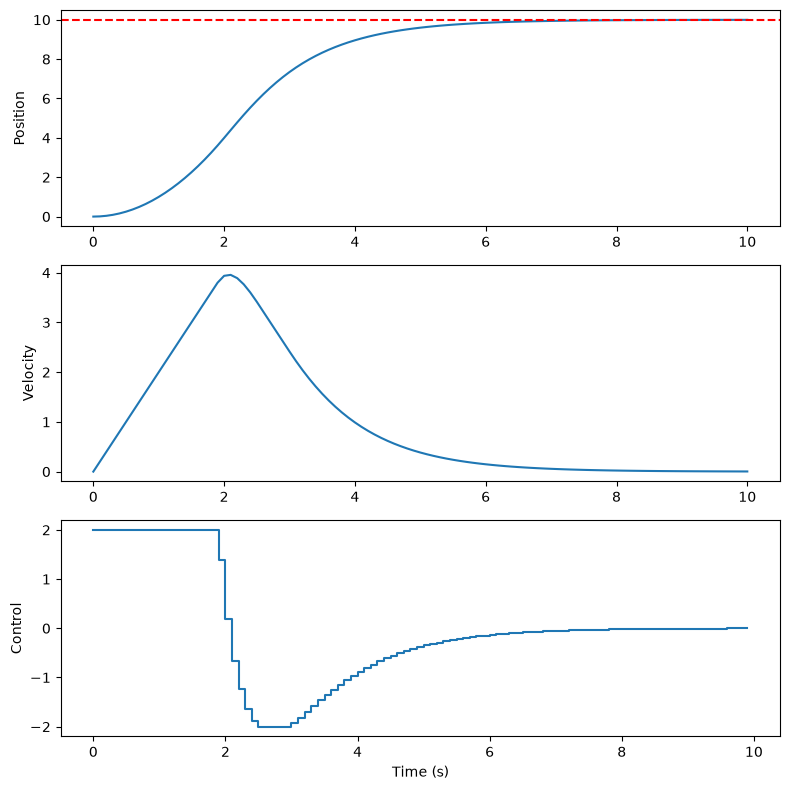

In [6]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.1
N = 100

A = np.array([
    [1, dt],
    [0, 1]
])

B = np.array([
    [0.5 * dt**2],
    [dt]
])

K = np.array([[2.0, 3.0]])

s = np.array([
    [0.0],
    [0.0]
])

s_ref = np.array([
    [10.0],
    [0.0]
])

u_min = -2.0
u_max = 2.0

states = [s.copy()]
controls = []


for _ in range(N):
    u_des = (K @ (s_ref - s)).item()

    # KKT solution
    u = np.clip(u_des, u_min, u_max)

    s = A @ s + B * u

    states.append(s.copy())
    controls.append(u)

states = np.array(states).squeeze(-1)
controls = np.array(controls)

t = np.arange(N + 1) * dt

fig, axes = plt.subplots(3, 1, figsize=(8, 8))

axes[0].plot(t, states[:, 0])
axes[0].axhline(10, color="r", linestyle="--")
axes[0].set_ylabel("Position")

axes[1].plot(t, states[:, 1])
axes[1].set_ylabel("Velocity")

axes[2].step(t[:-1], controls, where="post")
axes[2].set_ylabel("Control")
axes[2].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

Final position: 10.000004018485544
Final velocity: -2.912115801431077e-05
Maximum velocity: 3.0000000000000004
Minimum velocity: -0.10418863478994968
Maximum acceleration: 2.0
Minimum acceleration: -1.783405105594184


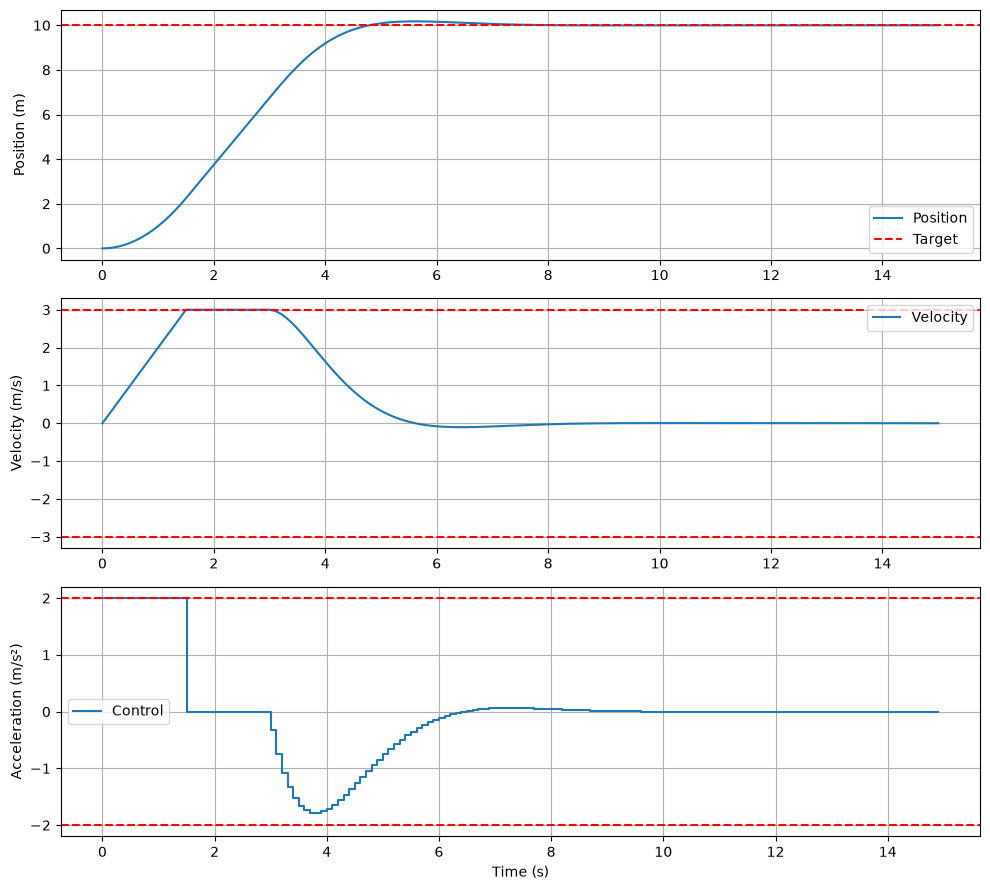

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations


# KKT-based QP solver
def solve_qp(H, f, C, d, tol=1e-7):
    n = H.shape[0]
    m = C.shape[0]

    f = f.reshape(-1, 1)
    d = d.reshape(-1, 1)

    for size in range(n + 1):
        for active in combinations(range(m), size):
            idx = list(active)

            A = C[idx, :]
            b = d[idx, :]

            KKT = np.block([
                [H, A.T],
                [A, np.zeros((size, size))]
            ])

            rhs = np.vstack([
                -f,
                b
            ])

            try:
                result = np.linalg.solve(KKT, rhs)
            except np.linalg.LinAlgError:
                continue

            U = result[:n]
            lam = result[n:]

            # Primal feasibility
            if np.any(C @ U - d > tol):
                continue

            # Dual feasibility
            if np.any(lam < -tol):
                continue

            # Stationarity
            residual = H @ U + f + A.T @ lam

            if np.linalg.norm(residual) > tol:
                continue

            return U, idx, lam

    raise RuntimeError("No valid KKT solution found")


# Simulation parameters
dt = 0.1
N = 2
steps = 150

# State-space model
A = np.array([
    [1, dt],
    [0,  1]
])

B = np.array([
    [0.5 * dt**2],
    [dt]
])

# Initial state
s = np.array([
    [0.0],
    [0.0]
])

# Reference state
s_ref = np.array([
    [10.0],
    [0.0]
])

# Cost matrices
Q = np.diag([10.0, 1.0])
R = np.array([[0.1]])

# Input constraints
u_min = -2.0
u_max =  2.0

# Velocity constraints
v_min = -3.0
v_max =  3.0


# Prediction matrices
F = np.vstack([
    A,
    A @ A
])

G = np.block([
    [B, np.zeros((2, 1))],
    [A @ B, B]
])


# QP cost matrices
Q_bar = np.kron(np.eye(N), Q)
R_bar = np.kron(np.eye(N), R)

S_ref = np.tile(s_ref, (N, 1))

H = 2 * (G.T @ Q_bar @ G + R_bar)


# Input constraints: C_u @ U <= d_u
C_u = np.vstack([
    np.eye(N),
    -np.eye(N)
])

d_u = np.vstack([
    np.full((N, 1), u_max),
    np.full((N, 1), -u_min)
])


# Velocity selection matrix
E = np.array([
    [0, 1, 0, 0],
    [0, 0, 0, 1]
])

C_v = np.vstack([
    E @ G,
    -E @ G
])

C = np.vstack([
    C_u,
    C_v
])


# MPC simulation
states = [s.ravel().copy()]
controls = []
active_history = []

for k in range(steps):

    # Linear cost term
    f = 2 * G.T @ Q_bar @ (F @ s - S_ref)

    # Velocity constraints
    d_v = np.vstack([
        np.full((N, 1), v_max) - E @ F @ s,
        E @ F @ s - np.full((N, 1), v_min)
    ])

    d = np.vstack([
        d_u,
        d_v
    ])

    # Solve QP using KKT conditions
    U, active, lam = solve_qp(H, f, C, d)

    # Apply only the first control input
    u = U[0, 0]

    # Update system
    s = A @ s + B * u

    states.append(s.ravel().copy())
    controls.append(u)
    active_history.append(active)


# Convert results``
states = np.array(states)
controls = np.array(controls)

t = np.arange(steps + 1) * dt


# Print results
print("Final position:", states[-1, 0])
print("Final velocity:", states[-1, 1])
print("Maximum velocity:", np.max(states[:, 1]))
print("Minimum velocity:", np.min(states[:, 1]))
print("Maximum acceleration:", np.max(controls))
print("Minimum acceleration:", np.min(controls))


# Visualization
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

# Position
axes[0].plot(t, states[:, 0], label="Position")
axes[0].axhline(10, color="r", linestyle="--", label="Target")
axes[0].set_ylabel("Position (m)")
axes[0].legend()
axes[0].grid(True)

# Velocity
axes[1].plot(t, states[:, 1], label="Velocity")
axes[1].axhline(v_max, color="r", linestyle="--")
axes[1].axhline(v_min, color="r", linestyle="--")
axes[1].set_ylabel("Velocity (m/s)")
axes[1].legend()
axes[1].grid(True)

# Acceleration
axes[2].step(t[:-1], controls, where="post", label="Control")
axes[2].axhline(u_max, color="r", linestyle="--")
axes[2].axhline(u_min, color="r", linestyle="--")
axes[2].set_ylabel("Acceleration (m/s²)")
axes[2].set_xlabel("Time (s)")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()